# Oasis Infobyte Internship
## Data Analytics – Level 1 Task 3
### Data Cleaning Project

Objective:Transform a messy dataset into a clean,
analysis-ready dataset using Python, Pandas and NumPy.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df=pd.read_csv("/content/dirty_cafe_sales.csv")

In [ ]:
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [ ]:
df.shape

(10000, 8)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
Transaction ID,0
Item,333
Quantity,138
Price Per Unit,179
Total Spent,173
Payment Method,2579
Location,3265
Transaction Date,159


In [ ]:
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100})
missing_report

,Missing Count,Missing Percentage
Transaction ID,0,0.00
Item,333,3.33
Quantity,138,1.38
Price Per Unit,179,1.79
Total Spent,173,1.73
Payment Method,2579,25.79
Location,3265,32.65
Transaction Date,159,1.59


In [ ]:
invalid_values = ["ERROR", "UNKNOWN", ""]
for column in df.columns:
    count = df[column].astype("string").str.strip().isin(invalid_values).sum()
    print(f"{column}: {count}")

Transaction ID: 0
Item: 636
Quantity: 341
Price Per Unit: 354
Total Spent: 329
Payment Method: 599
Location: 696
Transaction Date: 301


In [ ]:
categorical_columns = ["Item", "Payment Method", "Location"]
for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts(dropna=False))


 Item
Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
NaN          333
ERROR        292
Name: count, dtype: int64

 Payment Method
Payment Method
NaN               2579
Digital Wallet    2291
Credit Card       2273
Cash              2258
ERROR              306
UNKNOWN            293
Name: count, dtype: int64

 Location
Location
NaN         3265
Takeaway    3022
In-store    3017
ERROR        358
UNKNOWN      338
Name: count, dtype: int64


In [ ]:
df["Transaction Date"].head(15)

,Transaction Date
0,2023-09-08
1,2023-05-16
2,2023-07-19
3,2023-04-27
4,2023-06-11
5,2023-03-31
6,2023-10-06
7,2023-10-28
8,2023-07-28
9,2023-12-31


In [ ]:
df_raw = df.copy()
df_clean = df.copy()
print("Working copy created successfully!")

Working copy created successfully!


In [ ]:
invalid_values = ["ERROR", "UNKNOWN"]
for column in df_clean.columns:
    count = df_clean[column].astype("string").str.strip().isin(invalid_values).sum()
print(column, ":", count)

Transaction Date : 301


In [ ]:
for column in df_clean.columns:
    print("\nColumn:", column)
    print(df_clean[column].value_counts(dropna=False).head(15))


Column: Transaction ID
Transaction ID
TXN_1961373    1
TXN_4977031    1
TXN_4271903    1
TXN_7034554    1
TXN_3160411    1
TXN_2602893    1
TXN_4433211    1
TXN_6699534    1
TXN_4717867    1
TXN_2064365    1
TXN_2548360    1
TXN_3051279    1
TXN_7619095    1
TXN_9437049    1
TXN_8915701    1
Name: count, dtype: int64

Column: Item
Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
NaN          333
ERROR        292
Name: count, dtype: int64

Column: Quantity
Quantity
5          2013
2          1974
4          1863
3          1849
1          1822
UNKNOWN     171
ERROR       170
NaN         138
Name: count, dtype: int64

Column: Price Per Unit
Price Per Unit
3.0        2429
4.0        2331
2.0        1227
5.0        1204
1.0        1143
1.5        1133
ERROR       190
NaN         179
UNKNOWN     164
Name: count, dtype: int64

Column: Total Spent
Total Spent
6.0     979
12.0    939
3

In [ ]:
df_clean.replace(["ERROR", "UNKNOWN"], np.nan, inplace=True)

In [ ]:
df_clean.isnull().sum()

,0
Transaction ID,0
Item,969
Quantity,479
Price Per Unit,533
Total Spent,502
Payment Method,3178
Location,3961
Transaction Date,460


In [ ]:
missing_report = pd.DataFrame({"Missing Count": df_clean.isnull().sum(),"Missing Percentage": (df_clean.isnull().sum() / len(df_clean)) * 100
})
missing_report

,Missing Count,Missing Percentage
Transaction ID,0,0.00
Item,969,9.69
Quantity,479,4.79
Price Per Unit,533,5.33
Total Spent,502,5.02
Payment Method,3178,31.78
Location,3961,39.61
Transaction Date,460,4.60


In [ ]:

df_raw = df.copy()
df_clean = df.copy()
print("Working copy created successfully!")

Working copy created successfully!


In [ ]:
df_clean.replace(
    r'^\s*(ERROR|UNKNOWN)\s*$',
    np.nan,
    regex=True,
    inplace=True
)

print("Invalid values converted successfully!")

Invalid values converted successfully!


In [ ]:
missing_report = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().sum() / len(df_clean)
    ) * 100
})

missing_report

,Missing Count,Missing Percentage
Transaction ID,0,0.00
Item,969,9.69
Quantity,479,4.79
Price Per Unit,533,5.33
Total Spent,502,5.02
Payment Method,3178,31.78
Location,3961,39.61
Transaction Date,460,4.60


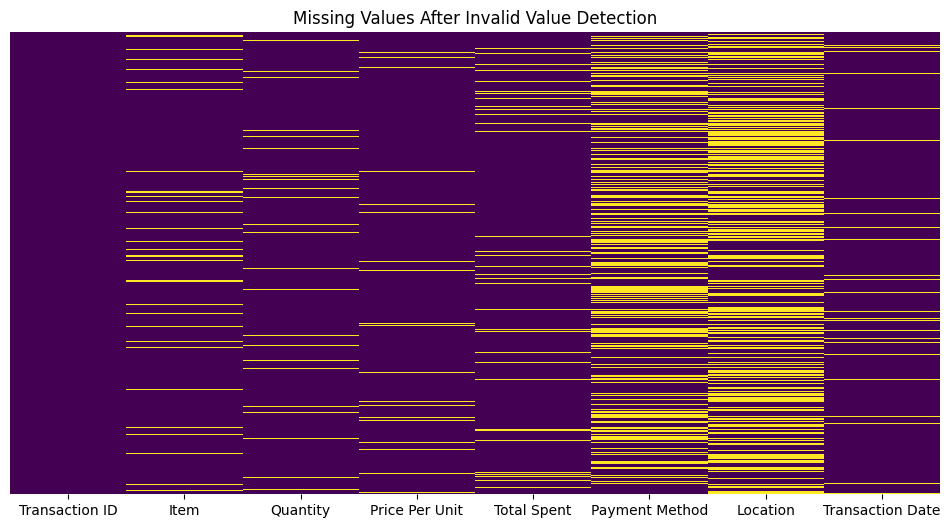

In [ ]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df_clean.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values After Invalid Value Detection")
plt.show()

In [ ]:
for column in df_clean.columns:
    error_count = (
        df_clean[column].astype("string").str.strip() == "ERROR"
    ).sum()

    unknown_count = (
        df_clean[column].astype("string").str.strip() == "UNKNOWN"
    ).sum()

    print(f"{column}")
    print("ERROR:", error_count)
    print("UNKNOWN:", unknown_count)
    print("-------------------")

Transaction ID
ERROR: 0
UNKNOWN: 0
-------------------
Item
ERROR: 0
UNKNOWN: 0
-------------------
Quantity
ERROR: 0
UNKNOWN: 0
-------------------
Price Per Unit
ERROR: 0
UNKNOWN: 0
-------------------
Total Spent
ERROR: 0
UNKNOWN: 0
-------------------
Payment Method
ERROR: 0
UNKNOWN: 0
-------------------
Location
ERROR: 0
UNKNOWN: 0
-------------------
Transaction Date
ERROR: 0
UNKNOWN: 0
-------------------


In [ ]:
df_clean.replace(
    ["ERROR", "UNKNOWN"],
    np.nan,
    inplace=True
)

print("Invalid values replaced successfully!")

Invalid values replaced successfully!


In [ ]:
missing_report = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

missing_report

,Missing Count,Missing Percentage
Transaction ID,0,0.00
Item,969,9.69
Quantity,479,4.79
Price Per Unit,533,5.33
Total Spent,502,5.02
Payment Method,3178,31.78
Location,3961,39.61
Transaction Date,460,4.60


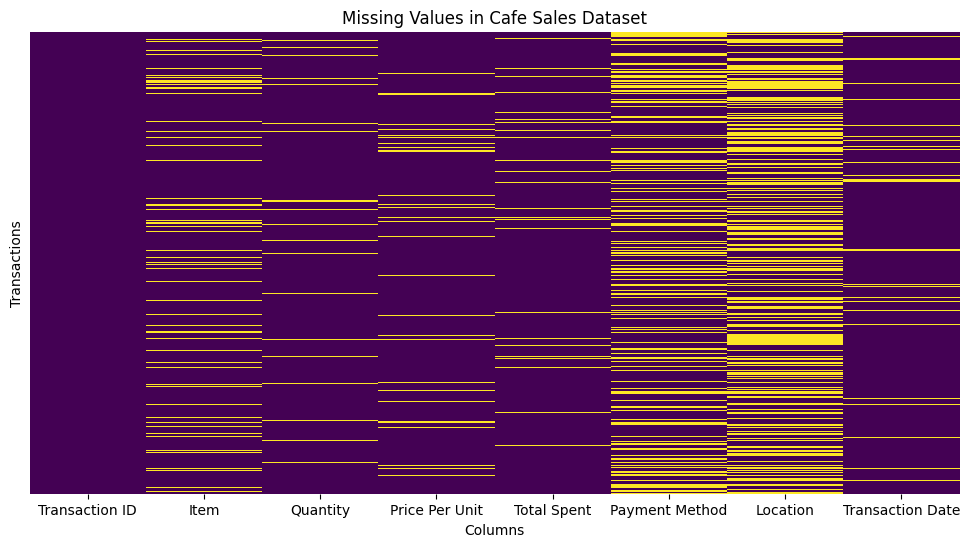

In [ ]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df_clean.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in Cafe Sales Dataset")
plt.xlabel("Columns")
plt.ylabel("Transactions")
plt.show()

In [ ]:
numeric_columns = [
    "Quantity",
    "Price Per Unit",
    "Total Spent"
]

for column in numeric_columns:
    df_clean[column] = pd.to_numeric(
        df_clean[column],
        errors="coerce"
    )

print("Numeric columns converted successfully!")

Numeric columns converted successfully!


In [ ]:
df_clean[numeric_columns].dtypes

,0
Quantity,float64
Price Per Unit,float64
Total Spent,float64


In [ ]:
df_clean[numeric_columns].isnull().sum()

,0
Quantity,479
Price Per Unit,533
Total Spent,502


In [ ]:
df_clean["Quantity"] = df_clean["Quantity"].fillna(
    df_clean["Quantity"].median()
)

df_clean["Price Per Unit"] = df_clean["Price Per Unit"].fillna(
    df_clean["Price Per Unit"].median()
)

print("Quantity and Price Per Unit cleaned!")

Quantity and Price Per Unit cleaned!


In [ ]:
df_clean["Total Spent"] = df_clean["Total Spent"].fillna(
    df_clean["Quantity"] * df_clean["Price Per Unit"]
)

print("Total Spent cleaned!")

Total Spent cleaned!


In [ ]:
df_clean[
    ["Quantity", "Price Per Unit", "Total Spent"]
].isnull().sum()

,0
Quantity,0
Price Per Unit,0
Total Spent,0


In [ ]:
categorical_columns = [
    'Item',
    'Payment Method',
    'Location'
]

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [ ]:
before_date_cleaning = len(df)

df = df.dropna(subset=['Transaction Date'])

print("Rows removed:", before_date_cleaning - len(df))

Rows removed: 159


In [ ]:
df.isnull().sum()

,0
Transaction ID,0
Item,0
Quantity,138
Price Per Unit,170
Total Spent,167
Payment Method,0
Location,0
Transaction Date,0


In [ ]:
for col in categorical_columns:
    df[col] = df[col].astype('string').str.strip().str.title()

In [ ]:
for col in categorical_columns:
    print(col)
    print(df[col].unique())

Item
<StringArray>
[  'Coffee',     'Cake',   'Cookie',    'Salad', 'Smoothie',  'Unknown',
 'Sandwich',    'Juice',    'Error',      'Tea']
Length: 10, dtype: string
Payment Method
<StringArray>
['Credit Card', 'Cash', 'Unknown', 'Digital Wallet', 'Error']
Length: 5, dtype: string
Location
<StringArray>
['Takeaway', 'In-Store', 'Unknown', 'Error']
Length: 4, dtype: string


In [ ]:
for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(col, "Outliers:", len(outliers))

TypeError: unsupported operand type(s) for -: 'str' and 'str'

In [ ]:
print(df[numeric_columns].dtypes)
print(df[numeric_columns].isnull().sum())

Quantity          object
Price Per Unit    object
Total Spent       object
dtype: object
Quantity          138
Price Per Unit    170
Total Spent       167
dtype: int64


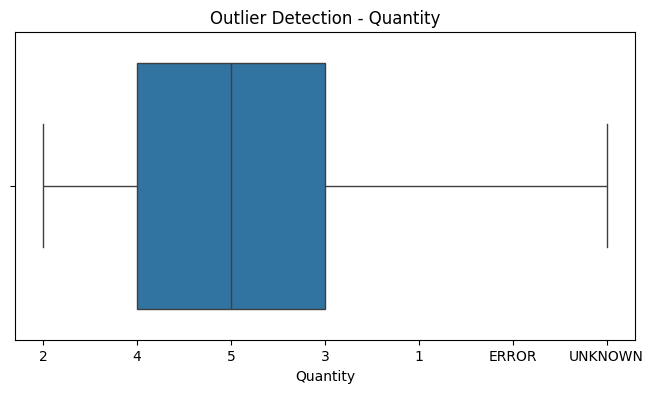

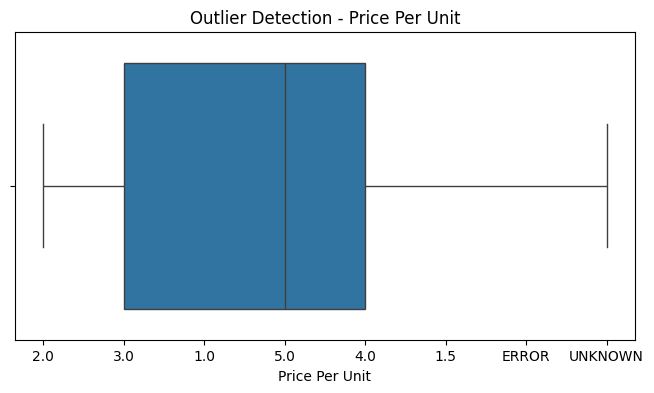

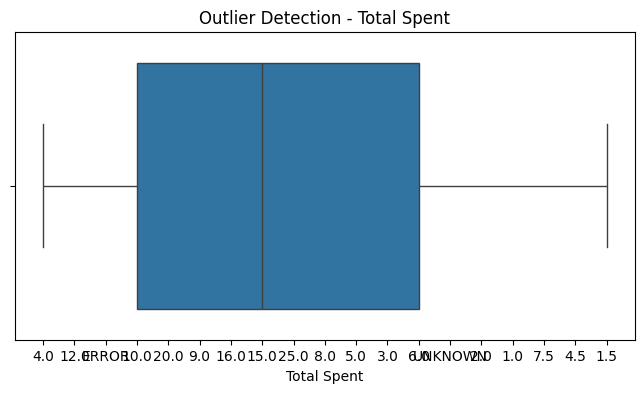

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in numeric_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[col])

    plt.title(f'Outlier Detection - {col}')

    plt.show()

In [ ]:
from scipy.stats import zscore

for col in numeric_columns:

    z_scores = zscore(df[col])

    outlier_count = (abs(z_scores) > 3).sum()

    print(col, "Z-score Outliers:", outlier_count)

TypeError: can only concatenate str (not "float") to str

In [ ]:
df['Expected Total'] = (
    df['Quantity'] * df['Price Per Unit']
)

df['Total Difference'] = (
    df['Total Spent'] - df['Expected Total']
)

display(df.head(10))

TypeError: can't multiply sequence by non-int of type 'str'

In [ ]:
df['Expected Total'] = (
    df['Quantity'] * df['Price Per Unit']
)

df['Total Difference'] = (
    df['Total Spent'] - df['Expected Total']
)

display(df.head(10))

TypeError: can't multiply sequence by non-int of type 'str'